# **Lab 4 | Analysing Time-Series Data**
**GY674 / GY675**

**Today:** Learn how to explore, analyse and visualise changes through time using Pandas and ERA5 temperature and precipitation data from Madagascar.

### What we'll learn

Our five-step data analysis workflow:

1. **Read** → Import time-series data into Python.
2. **Explore** → Understand the variables, dates and data structure.
3. **Prepare** → Convert dates and select time periods.
4. **Analyse** → Calculate monthly and annual statistics.
5. **Visualise** → Plot and interpret changes through time.

### How to use this notebook
- 👀 **Demo** – Follow along with the example.
- ✏️ **Your turn** – Modify or write some code yourself.
- ⭐ **Challenge** – Try a slightly harder problem using what you have learned.
- 🔎 **Final exercise** – Investigate your own question.

---

# **Step 1 | READ**

### Today's dataset

We'll use daily temperature and precipitation data from **ERA5 reanalysis** for Madagascar.

ERA5 combines observations and a weather model to provide a consistent record of past weather and climate.

👀 **Demo | Read the data**

1. Download the Madagascar CSV from the course GitHub.
2. Save it in your Google Drive folder `geo_python_labs_2026/data`.
3. Connect Colab to Google Drive and read the CSV using Pandas.

Remember: Your file path must match where you saved the data.

In [1]:
# Import packages
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Connect Google Drive
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
# Define the data directory
data_dir = "/content/drive/MyDrive/geo_python_labs_2026/data/"

# Read the CSV
df = pd.read_csv(
    data_dir + "Antananarivo_Madagascar_ERA5_daily_1941-2025.csv"
)

df

,Date,Temperature_DegC,Precipitation_mm
0,01/01/1941,19.14,2.31
1,02/01/1941,19.63,14.72
2,03/01/1941,18.25,0.35
3,04/01/1941,16.54,1.50
4,05/01/1941,14.76,5.64
...,...,...,...
31041,27/12/2025,18.60,20.33
31042,28/12/2025,20.31,7.06
31043,29/12/2025,20.44,8.58
31044,30/12/2025,21.88,0.80


---

# **Step 2 | EXPLORE**

**What's in our dataset?**

Before analysing data, we need to understand what we have.

✏️ **Your turn | Explore the data**

Using commands from Lab 3:

1. Display the first and last five rows.
2. Check the number of rows and columns.
3. Check the column names and data types.
4. Explore the summary statistics.

**Think about:**
- What period does the dataset cover?
- What are the units of temperature and precipitation?
- What data type is the `Date` column? Is Python recognising it as a date?

In [4]:
# Hint: .head(), .tail(), .shape, .info(), .describe()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31046 entries, 0 to 31045
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              31046 non-null  object 
 1   Temperature_DegC  31046 non-null  float64
 2   Precipitation_mm  31046 non-null  float64
dtypes: float64(2), object(1)
memory usage: 727.8+ KB


In [5]:
df.describe()

,Temperature_DegC,Precipitation_mm
count,31046.000000,31046.000000
mean,17.498629,3.064651
std,2.782210,7.421199
min,9.600000,0.000000
25%,15.180000,0.030000
50%,18.110000,0.310000
75%,19.710000,2.237500
max,24.610000,145.250000


---

# **Step 3 | PREPARE**

**How do we prepare dates for time-series analysis?**

In Step 2, you may have noticed that Python reads our `Date` column as an `object` (text), rather than a date.

Before analysing changes through time, we need to convert it into a format Python understands.

👀 **Demo | Convert text into dates**

Pandas provides `pd.to_datetime()` to convert text into dates.

Our dates use the format **DD/MM/YYYY** (e.g. 01/01/1941).

**Date formatting:** The `format="%d/%m/%Y"` argument tells pandas how dates are written in the CSV: `%d` = day, `%m` = month, and `%Y` = four-digit year.

For other date formats, see the [Python date and time formatting reference](https://docs.python.org/3/library/datetime.html#strftime-and-strptime-format-codes).

In [6]:
# Convert the Date column to datetime
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")

# Check the data types again
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31046 entries, 0 to 31045
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Date              31046 non-null  datetime64[ns]
 1   Temperature_DegC  31046 non-null  float64       
 2   Precipitation_mm  31046 non-null  float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 727.8 KB


👀 **Demo | Set dates as the index**

Until now, our DataFrames have used row numbers (0, 1, 2...) as the index.

By making `Date` the index, we can easily select time periods and calculate monthly or annual statistics using Pandas.

In [8]:
# Set Date as the index (instead of row numbers)
df = df.set_index("Date")
df

,Temperature_DegC,Precipitation_mm
Date,,
1941-01-01,19.14,2.31
1941-01-02,19.63,14.72
1941-01-03,18.25,0.35
1941-01-04,16.54,1.50
1941-01-05,14.76,5.64
...,...,...
2025-12-27,18.60,20.33
2025-12-28,20.31,7.06
2025-12-29,20.44,8.58


---

# **Step 4 | ANALYSE**

**How can we analyse changes through time?**

Now that our dates are prepared, we can select different time periods and calculate statistics.

### 4.0 | Emergency reset (if needed)

If your DataFrame is no longer working as expected, run the code below to reload the original data and prepare the dates again.

**Only run this cell if you need to reset your data.**

In [9]:
# Define the data directory
data_dir = "/content/drive/MyDrive/geo_python_labs_2026/data/"

# Read the CSV
df = pd.read_csv(
    data_dir + "Antananarivo_Madagascar_ERA5_daily_1941-2025.csv"
)

# Convert the Date column to datetime
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")

# Set Date as the index
df = df.set_index("Date")

df.head()

,Temperature_DegC,Precipitation_mm
Date,,
1941-01-01,19.14,2.31
1941-01-02,19.63,14.72
1941-01-03,18.25,0.35
1941-01-04,16.54,1.50
1941-01-05,14.76,5.64


### 4.1 | Selecting time periods

👀 **Demo | Select a year**

Pandas allows us to select dates using `.loc[]`.

Let's select all daily observations from 2020.

In [10]:
# Select all days in 2020
df_2020 = df.loc["2020"]

df_2020

,Temperature_DegC,Precipitation_mm
Date,,
2020-01-01,21.61,21.09
2020-01-02,20.73,17.90
2020-01-03,19.20,59.65
2020-01-04,20.66,20.27
2020-01-05,21.03,2.69
...,...,...
2020-12-27,19.47,18.26
2020-12-28,20.27,8.09
2020-12-29,20.65,1.10


✏️ **Your turn | Select different periods**

1. Select all observations from 2025.
2. Select January 2025.
3. Select the period 2020–2025.

Hint: Use `.loc[]` with dates.

In [11]:
# 1.
df.loc["2025"]

# 2.
df.loc["2025-01"]

# Try selecting different time periods
df.loc["2020":"2025"]

,Temperature_DegC,Precipitation_mm
Date,,
2020-01-01,21.61,21.09
2020-01-02,20.73,17.90
2020-01-03,19.20,59.65
2020-01-04,20.66,20.27
2020-01-05,21.03,2.69
...,...,...
2025-12-27,18.60,20.33
2025-12-28,20.31,7.06
2025-12-29,20.44,8.58


### 4.2 | Calculating monthly statistics

Daily data can be useful, but sometimes we want to understand changes over months or years.

Pandas uses `.resample()` to group observations into time periods.

👀 **Demo | Calculate monthly temperature and rainfall**

Remember:
- **Temperature:** Calculate the mean (°C).
- **Precipitation:** Calculate the total (mm).

**Resampling frequencies:** The `"MS"` in `.resample("MS")` specifies the time interval used to group observations. Common options include:

- `"W"` = Weekly (weeks ending Sunday)
- `"MS"` = Month start
- `"YS"` = Year start

For other frequencies, see the [pandas time-series frequency aliases documentation](https://pandas.pydata.org/docs/user_guide/timeseries.html#dateoffset-objects).

In [12]:
# Calculate monthly mean temperature
monthly_temp = df["Temperature_DegC"].resample("MS").mean()

monthly_temp

,Temperature_DegC
Date,
1941-01-01,18.553226
1941-02-01,18.373571
1941-03-01,18.992581
1941-04-01,17.012333
1941-05-01,15.730000
...,...
2025-08-01,14.539032
2025-09-01,17.275000
2025-10-01,19.104194


<Axes: xlabel='Date'>

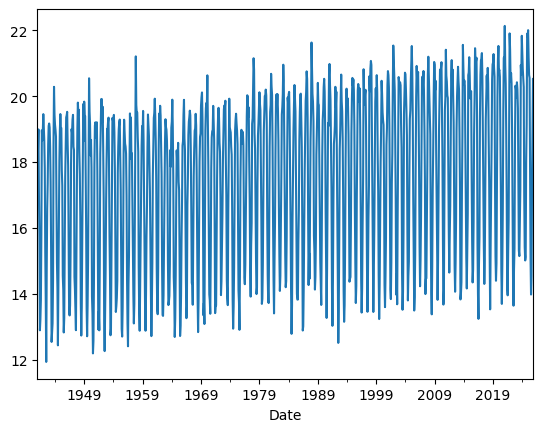

In [13]:
# quick plot monthly
monthly_temp.plot()

✏️ **Your turn | Monthly precipitation**

Using the monthly temperature example above:

1. Calculate monthly precipitation totals using `.resample()`.
2. Display the first five months.
3. Why do we use `.sum()` for precipitation but `.mean()` for temperature?

**Hint:** Use `"MS"` for monthly resampling.

In [21]:
# Calculate monthly precipitation totals
monthly_rainfall = df["Precipitation_mm"].resample("MS").sum()

# Display the first five months
monthly_rainfall.head()

,Precipitation_mm
Date,
1941-01-01,152.33
1941-02-01,151.13
1941-03-01,295.04
1941-04-01,259.53
1941-05-01,26.64


<Axes: xlabel='Date'>

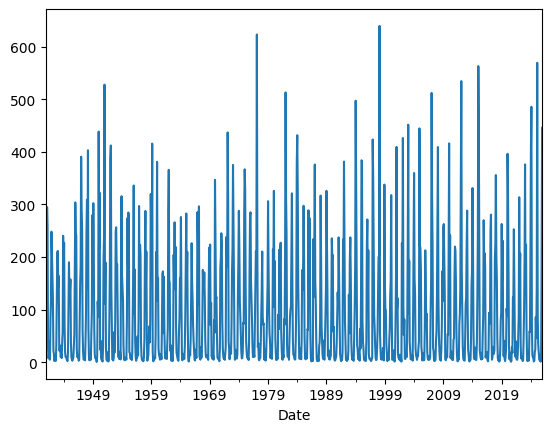

In [22]:
# Quick plot
monthly_rainfall.plot()

✏️ **Your turn | Annual statistics**

Using what you've learned about `.resample()`:

1. Calculate annual mean temperature.
2. Calculate annual precipitation totals.
3. Display the first five years.

**Hint:** Use `"YS"` for Year Start.

In [23]:
# Calculate annual mean temperature
annual_temp = df["Temperature_DegC"].resample("YS").mean()

# Calculate annual precipitation totals
annual_rainfall = df["Precipitation_mm"].resample("YS").sum()

# Display the results
annual_temp.head()
annual_rainfall.head()

,Precipitation_mm
Date,
1941-01-01,1398.44
1942-01-01,919.62
1943-01-01,960.63
1944-01-01,834.82
1945-01-01,742.41


✏️ **Your turn | Selecting a period**

We've calculated annual statistics for 1941–2025. What if we only want to analyse recent decades?

1. Select annual mean temperature for **1991–2020**.
2. Calculate the average temperature over this 30-year period.
3. Repeat for annual precipitation totals, calculating the average annual rainfall.

**Hint:** Use `.loc[]` to select years and `.mean()` to calculate the period average.

In [24]:
# 1. Select annual mean temperature for 1991–2020
temp_1991_2020 = annual_temp.loc["1991":"2020"]

# 2. Calculate the average temperature over this 30-year period
temp_1991_2020.mean()

# 3. Repeat for annual precipitation totals, calculating average annual rainfall
rainfall_1991_2020 = annual_rainfall.loc["1991":"2020"]
rainfall_1991_2020.mean()

np.float64(1099.7596666666666)

⭐ **Optional challenge | Meteorological seasons**

Climate scientists often analyse data by season: **DJF, MAM, JJA and SON**.

DJF is tricky because December belongs with January and February of the following year.

Pandas handles this using `QS-DEC`:
- `QS` = Quarter Start (three-month periods).
- `DEC` = Quarters start in December.

This correctly groups all four meteorological seasons.

**Your challenge:**
1. Calculate seasonal mean temperature using `.resample("QS-DEC").mean()`.
2. Adapt the code to calculate seasonal precipitation totals.
3. What problem might occur with the first or last season in the dataset?

**Reference:** [Pandas time-series frequency aliases](https://pandas.pydata.org/docs/user_guide/timeseries.html#dateoffset-objects)

In [25]:
# 1. Calculate seasonal mean temperature
seasonal_temp = df["Temperature_DegC"].resample("QS-DEC").mean()

seasonal_temp.head()

,Temperature_DegC
Date,
1940-12-01,18.467966
1941-03-01,17.247500
1941-06-01,13.310870
1941-09-01,17.824505
1941-12-01,19.149778


In [26]:
# 2. Calculate seasonal precipitation totals
seasonal_rainfall = df["Precipitation_mm"].resample("QS-DEC").sum()

seasonal_rainfall.head()

,Precipitation_mm
Date,
1940-12-01,303.46
1941-03-01,581.21
1941-06-01,63.50
1941-09-01,202.04
1941-12-01,619.43


In [27]:
# 3. The first and last DJF seasons are incomplete.

# December 1940 and January–February 2026 are missing.
# Solution: analyse only complete winters (1941/42 to 2024/25).

---

# **Step 5 | VISUALISE**

**How can we communicate patterns and changes through time?**

We've explored, prepared and analysed our temperature and precipitation data. Now we'll turn our results into clear, informative figures.

We'll use **Matplotlib**, a Python library for creating and customising visualisations.

In this section, we'll learn to:
- Create time-series plots.
- Improve figure design using colours, labels, legends and other settings.
- Compare data across different timescales.
- Export processed data as CSV files and save high-quality figures.

**Remember:** Pandas is great for quickly exploring data (`df.plot()`), while Matplotlib gives us more control over how our results are presented.


### 5.1 | Your first time-series plot

👀 **Demo** – Let's plot annual mean temperature in Antananarivo, Madagascar, using Matplotlib.

Remember from Lab 1: `fig` represents the overall figure, while `ax` represents the plotting area.

<img src="data:image/svg+xml;base64, PHN2ZyBmb250LWZhbWlseT0iLWFwcGxlLXN5c3RlbS1ib2R5LCB1aS1zYW5zLXNlcmlmLCAtYXBwbGUtc3lzdGVtLCBzeXN0ZW0tdWksICZxdW90O1NlZ29lIFVJJnF1b3Q7LCBIZWx2ZXRpY2EsICZxdW90O0FwcGxlIENvbG9yIEVtb2ppJnF1b3Q7LCBBcmlhbCwgc2Fucy1zZXJpZiwgJnF1b3Q7U2Vnb2UgVUkgRW1vamkmcXVvdDssICZxdW90O1NlZ29lIFVJIFN5bWJvbCZxdW90OyIgZm9udC13ZWlnaHQ9IjQwMCIgZGF0YS1kLWNvbXBvbmVudD0ic3ZnIiBmaWxsPSJjdXJyZW50Q29sb3IiIHN0eWxlPSJjb2xvcjpyZ2IoMTMsIDEzLCAxMykiIHZpZXdCb3g9IjAgMCAzNDAgMTg4IiB3aWR0aD0iMTAwJSIgeG1sbnM9Imh0dHA6Ly93d3cudzMub3JnLzIwMDAvc3ZnIj48cmVjdCB4PSI1IiB5PSI1IiB3aWR0aD0iMzMwIiBoZWlnaHQ9IjE3NyIgcng9IjUiIGZpbGw9IiNlOWVmZjYiIHN0cm9rZT0iIzUyNzY5YSIgc3Ryb2tlLXdpZHRoPSIyIi8+PHRleHQgeD0iMTciIHk9IjIzIiBmaWxsPSIjMjg0YzczIiBmb250LXNpemU9IjExIiBmb250LXdlaWdodD0iYm9sZCI+ZmlnIOKAlCBlbnRpcmUgZmlndXJlPC90ZXh0PjxyZWN0IHg9IjU3IiB5PSIzNiIgd2lkdGg9IjI2MCIgaGVpZ2h0PSIxMTgiIHJ4PSIyIiBmaWxsPSIjZmZmZmZmIiBzdHJva2U9IiMyZDdiYmEiIHN0cm9rZS13aWR0aD0iMiIvPjx0ZXh0IHg9IjY5IiB5PSI1MyIgZmlsbD0iIzJkN2JiYSIgZm9udC1zaXplPSIxMSIgZm9udC13ZWlnaHQ9ImJvbGQiPmF4IOKAlCBwbG90dGluZyBhcmVhPC90ZXh0PjxsaW5lIHgxPSI4MCIgeDI9IjMwMCIgeTE9Ijc4IiB5Mj0iNzgiIHN0cm9rZT0iI2U1ZTdlYiIvPjxsaW5lIHgxPSI4MCIgeDI9IjMwMCIgeTE9IjEwNSIgeTI9IjEwNSIgc3Ryb2tlPSIjZTVlN2ViIi8+PGxpbmUgeDE9IjgwIiB4Mj0iMzAwIiB5MT0iMTMyIiB5Mj0iMTMyIiBzdHJva2U9IiNlNWU3ZWIiLz48bGluZSB4MT0iODAiIHkxPSI2MyIgeDI9IjgwIiB5Mj0iMTM2IiBzdHJva2U9IiM2ODc3ODkiIHN0cm9rZS13aWR0aD0iMS41Ii8+PGxpbmUgeDE9IjgwIiB5MT0iMTM2IiB4Mj0iMzAwIiB5Mj0iMTM2IiBzdHJva2U9IiM2ODc3ODkiIHN0cm9rZS13aWR0aD0iMS41Ii8+PHBhdGggZD0iTTgwIDExOSBMMTE1IDExMCBMMTUxIDExNiBMMTg4IDgzIEwyMjMgOTIgTDI2MSA2NyBMMzAwIDc1IiBmaWxsPSJub25lIiBzdHJva2U9IiMyNjg0YzIiIHN0cm9rZS13aWR0aD0iMi44IiBzdHJva2UtbGluZWpvaW49InJvdW5kIi8+PHRleHQgeD0iMTg1IiB5PSIxNjkiIHRleHQtYW5jaG9yPSJtaWRkbGUiIGZpbGw9IiMyODRjNzMiIGZvbnQtc2l6ZT0iMTAiPmZpZ3NpemU9KDksIDQpIOKGkiB3aWR0aCDDlyBoZWlnaHQgaW4gaW5jaGVzPC90ZXh0Pjwvc3ZnPg==" width="600">

The `ax.plot()` function creates a line plot:

- `annual_temp.index` – the dates (years) on the **x-axis**.
- `annual_temp` – the annual mean temperature values on the **y-axis**.
- `color="tab:red"` – sets the line colour to a nice red.

The general structure is `ax.plot(x, y)`, where `x` and `y` are the data to plot.

**Saving your figure**

Use `fig.savefig()` to save your plot as an image file that can be used in reports, presentations or assignments.

- **File path** – where to save the figure, including its filename.
- **`dpi=300`** – saves a high-resolution image suitable for reports and presentations.
- **`bbox_inches="tight"`** – removes unnecessary whitespace around the figure.

You can save figures in different formats, including `.png`, `.jpg`, `.pdf` and `.svg`, simply by changing the file extension.

In [28]:
# Calculate annual mean temperature (same as above, but here in-case you get lost)
annual_temp = df["Temperature_DegC"].resample("YS").mean()

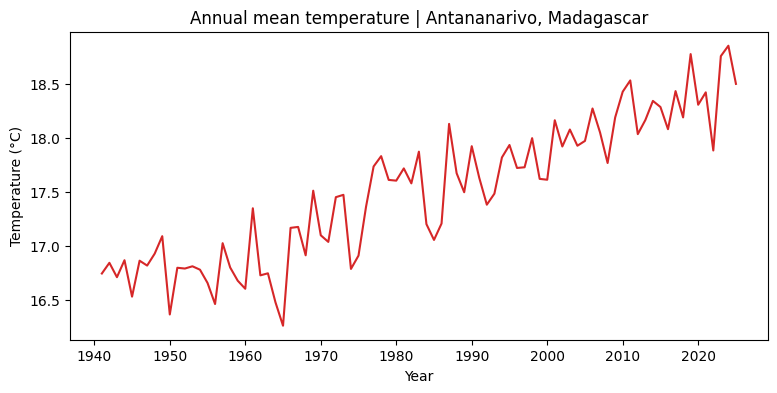

In [29]:
# Create a figure and axes
fig, ax = plt.subplots(figsize=(9, 4))

# Plot annual mean temperature
ax.plot(annual_temp.index, annual_temp, color="tab:red")

# Add title and axis labels
ax.set(
    title="Annual mean temperature | Antananarivo, Madagascar",
    xlabel="Year",
    ylabel="Temperature (°C)"
)

# Save the figure to Google Drive
fig.savefig(
    "/content/drive/MyDrive/geo_python_labs_2026/outputs/annual_temperature.png",
    dpi=300, bbox_inches="tight"
)

# Display the figure
plt.show()

### 5.2 | Customising your figure

A good visualisation should be **clear, readable and informative**.

Matplotlib offers many options for customising plots. You don't need to memorise them — knowing how to find and use documentation is an important Python skill.

📖 **Explore:** [Matplotlib `ax.plot()` documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.plot.html)

Remember the basic structure:

`ax.plot(x, y, **kwargs)`

- `x` – Values on the horizontal axis (our dates).
- `y` – Values on the vertical axis (our temperature).
- `**kwargs` – Additional options to customise the plot.

**Quick reference – common plotting options**

| Option | What it controls | Examples |
|---|---|---|
| `color` | Line colour | `"tab:red"`, `"tab:blue"`, `"black"` |
| `linestyle` | Line style | `"-"` solid, `"--"` dashed, `":"` dotted |
| `linewidth` | Line thickness | `1`, `2`, `3` |
| `marker` | Symbols at data points | `"o"` circle, `"s"` square, `"^"` triangle |
| `markersize` | Symbol size | `3`, `5`, `8` |
| `alpha` | Transparency | `0.5`, `0.8`, `1.0` |

For more options, explore [Matplotlib colours](https://matplotlib.org/stable/gallery/color/named_colors.html) and [line styles and markers](https://matplotlib.org/stable/gallery/lines_bars_and_markers/index.html).

✏️ **Your turn** – The code below recreates your annual temperature plot. Experiment with its appearance to improve the visualisation.

1. Change at least three plotting options using the quick reference or documentation.
2. Experiment with the figure size and add a grid (`ax.grid(alpha=0.3)`).
3. Improve the title and axis labels.

**Think about:** Which design choices make your figure easier to interpret?

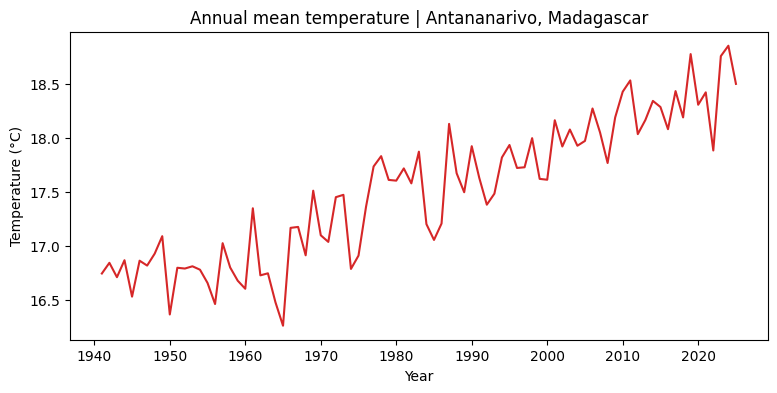

In [30]:
### I give you the basic plot and data again below, but have a go and changing the parameters, titles, etc.

# Recalculate annual mean temperature
annual_temp = df["Temperature_DegC"].resample("YS").mean()

# Create a figure and axes
fig, ax = plt.subplots(figsize=(9, 4))

# Plot annual mean temperature
ax.plot(annual_temp.index, annual_temp, color="tab:red")

# Add title and axis labels
ax.set(
    title="Annual mean temperature | Antananarivo, Madagascar",
    xlabel="Year",
    ylabel="Temperature (°C)"
)

# Display the figure
plt.show()

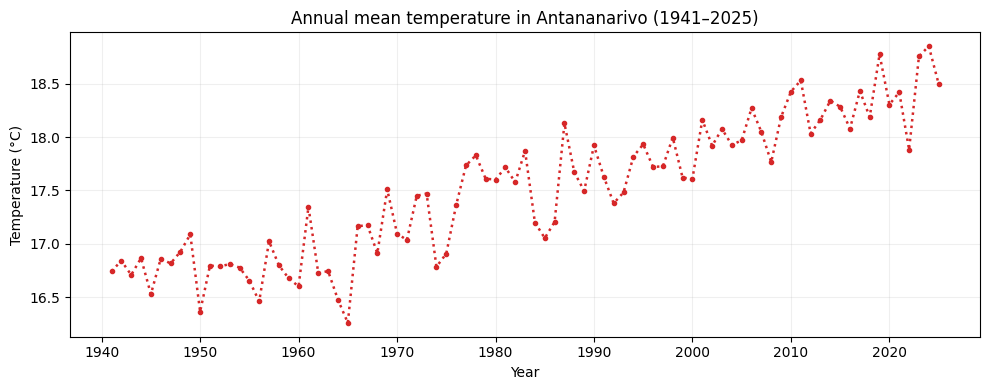

In [31]:
### Solution
# Recalculate annual mean temperature
annual_temp = df["Temperature_DegC"].resample("YS").mean()

# Create a figure and axes
fig, ax = plt.subplots(figsize=(10, 4))

# Plot annual mean temperature
ax.plot(
    annual_temp.index,
    annual_temp,
    color="tab:red",
    linewidth=1.8,
    linestyle=":",
    marker="o",
    markersize=3
)

# Add title and axis labels
ax.set(
    title="Annual mean temperature in Antananarivo (1941–2025)",
    xlabel="Year",
    ylabel="Temperature (°C)"
)

# Improve readability
ax.grid(True, alpha=0.2)

# Adjust layout
plt.tight_layout()
plt.show()

### 5.3 | Comparing daily and monthly temperature

**How does the timescale of our data affect the patterns we see?**

Daily temperature varies considerably, making longer-term patterns difficult to identify. By calculating monthly averages, we can smooth out some of this short-term variability.

👀 **Demo** – Let's compare daily temperature with monthly mean temperature for 2020–2025.

We'll introduce two new plotting features:
- `label=` – Gives each line a name.
- `ax.legend()` – Displays those names in a legend.

Notice how we use `ax.plot()` twice to add two lines to the same figure.

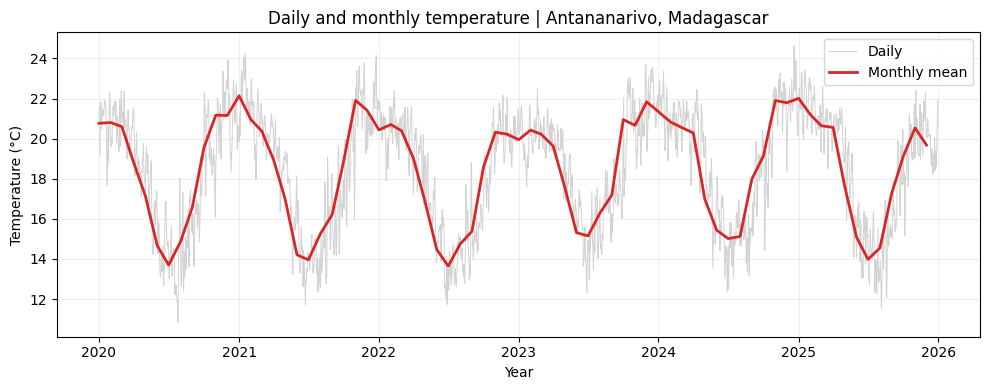

In [32]:
# Select daily temperature for 2020–2025
daily_temp = df.loc["2020":"2025", "Temperature_DegC"]

# Calculate monthly mean temperature
monthly_temp = df["Temperature_DegC"].resample("MS").mean()
monthly_temp = monthly_temp.loc["2020":"2025"]

# Create figure and axes
fig, ax = plt.subplots(figsize=(10, 4))

# Plot daily and monthly temperature
ax.plot(daily_temp.index, daily_temp,
        color="lightgray", linewidth=0.7, label="Daily")

ax.plot(monthly_temp.index, monthly_temp,
        color="tab:red", linewidth=2, label="Monthly mean")

# Add title and labels
ax.set(
    title="Daily and monthly temperature | Antananarivo, Madagascar",
    xlabel="Year",
    ylabel="Temperature (°C)"
)

# Add legend and grid
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### 5.4 | Creating multi-panel figures

**How can we compare different climate variables in one figure?**

Sometimes it is clearer to display related variables in separate panels rather than plotting everything on the same axes.

👀 **Demo** – Let's create a figure showing annual mean temperature and annual total precipitation in Antananarivo, Madagascar.

We'll introduce:

- `plt.subplots(2, 1)` – Creates two rows of plots in one figure.
- `ax[0]` – Refers to the top panel.
- `ax[1]` – Refers to the bottom panel.
- `sharex=True` – Gives both panels the same time axis.

Notice that we're using the same `.resample()` and `ax.plot()` commands we've already learned.

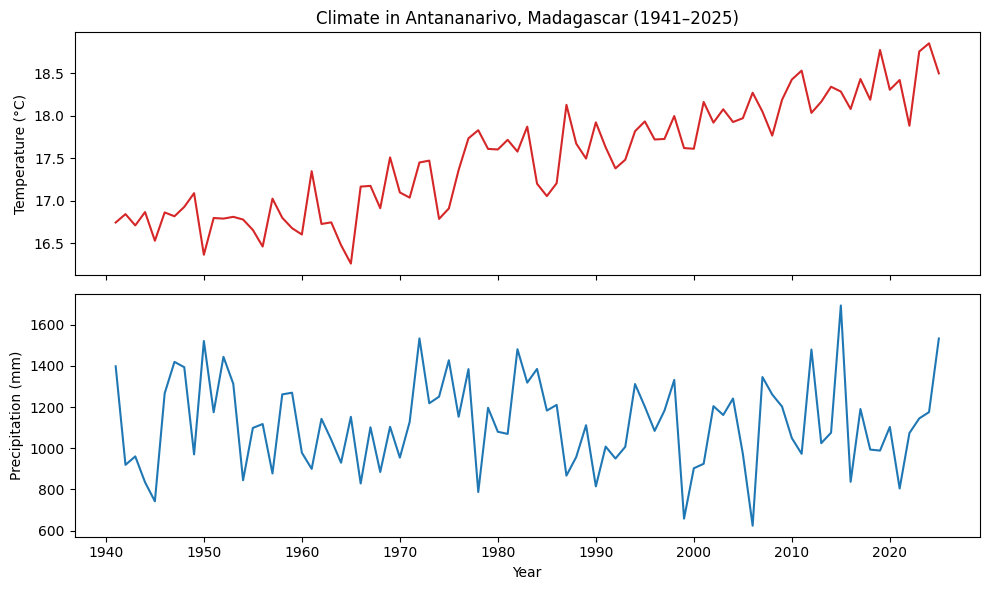

In [33]:
# Calculate annual climate statistics
annual_temp = df["Temperature_DegC"].resample("YS").mean()
annual_rainfall = df["Precipitation_mm"].resample("YS").sum()

# Create a figure with two panels
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Top panel: Annual mean temperature
ax[0].plot(annual_temp.index, annual_temp, color="tab:red")
ax[0].set(
    title="Climate in Antananarivo, Madagascar (1941–2025)",
    ylabel="Temperature (°C)"
)

# Bottom panel: Annual total precipitation
ax[1].plot(annual_rainfall.index, annual_rainfall, color="tab:blue")
ax[1].set(
    xlabel="Year",
    ylabel="Precipitation (mm)"
)

# Improve layout and display
plt.tight_layout()
plt.show()

✏️ **Your turn** – Using the working example above:

1. Add a subtle grid to both panels using `ax[0].grid(alpha=0.2)` and `ax[1].grid(alpha=0.2)`.
2. Experiment with the colours and line widths.
3. Try changing the precipitation plot from a line to a bar chart using `ax[1].bar()` instead of `ax[1].plot()`.
4. Try changing `sharex=True` to `sharey=True`. What happens? Why might this be inappropriate for our two climate variables?

**Think about:** Which type of plot works best for showing annual precipitation totals, and why?

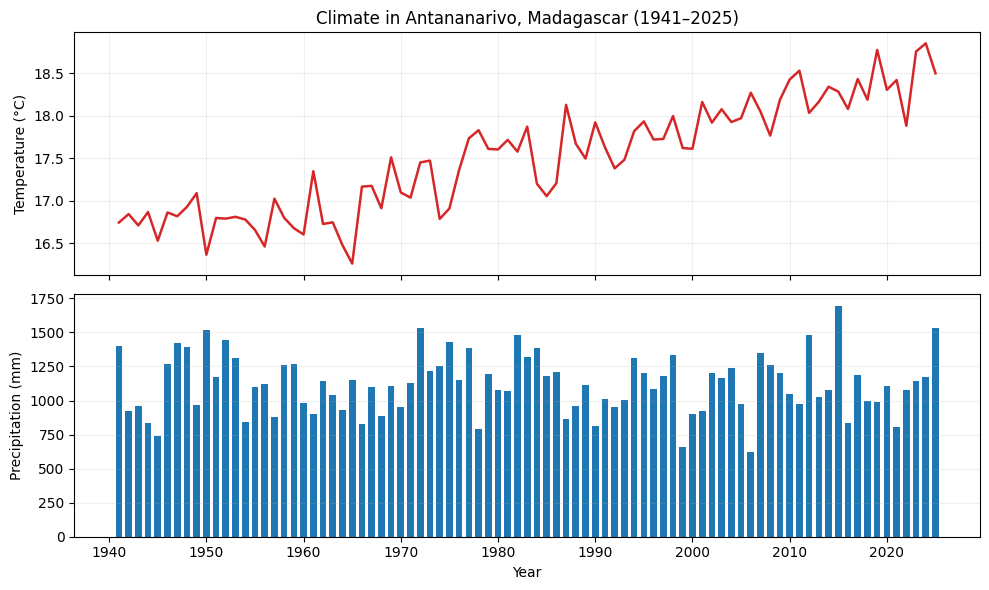

In [34]:
### Solution ####

# Calculate annual climate statistics
annual_temp = df["Temperature_DegC"].resample("YS").mean()
annual_rainfall = df["Precipitation_mm"].resample("YS").sum()

# Create a figure with two panels
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Top panel: Annual mean temperature
ax[0].plot(
    annual_temp.index,
    annual_temp,
    color="tab:red",
    linewidth=1.8
)
ax[0].set(
    title="Climate in Antananarivo, Madagascar (1941–2025)",
    ylabel="Temperature (°C)"
)
ax[0].grid(alpha=0.2)

# Bottom panel: Annual total precipitation
ax[1].bar(
    annual_rainfall.index,
    annual_rainfall,
    color="tab:blue",
    width=250
)
ax[1].set(
    xlabel="Year",
    ylabel="Precipitation (mm)"
)
ax[1].grid(axis="y", alpha=0.2)

# Improve layout and display
plt.tight_layout()
plt.show()

### 5.5 | Saving your results

So far, we've analysed climate data and created figures in Python. But what if we want to use our results in a report, presentation or another application?

We can **export our results** directly to Google Drive:

- **CSV (.csv)** – Save processed data for use in Excel or other software.
- **PNG (.png)** – Save figures for reports and presentations.

👀 **Demo:** Let's save our annual temperature and precipitation data, along with a figure.

In [35]:
# Save processed climate data as CSV files

output_dir = "/content/drive/MyDrive/geo_python_labs_2026/outputs/"

annual_temp.to_csv(output_dir + "antananarivo_annual_temperature.csv")
annual_rainfall.to_csv(output_dir + "antananarivo_annual_precipitation.csv")

---

# **Final exercise | Comparing climates across Madagascar**

**How does climate differ between locations in Madagascar?**

Now it's your turn to apply what you've learned! Using ERA5 daily climate data (1941–2025), compare **Toamasina** on the east coast and **Toliara** in the southwest.

The map below shows the locations and their Köppen–Geiger climate classifications.

<img src="https://raw.githubusercontent.com/shaunharrigan/maynooth-geo-python/main/data/madagascar_climate/station_map.png" width="550" alt="Köppen–Geiger climate classification and station locations in Madagascar">

Follow these steps for your analysis:

1. **READ & PREPARE** – For each station:
   - Read the CSV file using `pd.read_csv()`.
   - Convert the `Date` column to datetime using `pd.to_datetime()`.
   - Set `Date` as the index using `.set_index()`.

2. **ANALYSE** – Select either temperature or precipitation, then use `.resample()` to calculate **annual mean temperature** or **annual total precipitation** for both stations.

3. **VISUALISE** – Plot both stations on one figure, with clear labels, colours and a legend.

4. **INTERPRET** – What differences do you notice? How might their geographical locations help explain them?

5. **EXPORT** – Save your annual climate data as two CSV files and your comparison figure as a PNG in the `outputs/` folder on Google Drive.

💡 **Important:** You don't need to write everything from scratch! Go back through this notebook, **find the code you need, copy it and adapt it** to your new datasets. This is an essential Python skill.


In [36]:
# FINAL EXERCISE: Comparing climates across Madagascar

# Dataset folder
data_dir = "/content/drive/MyDrive/geo_python_labs_2026/data/"

# File paths for the two stations
toamasina_file_path = data_dir + "Toamasina_Madagascar_ERA5_daily_1941-2025.csv"
toliara_file_path = data_dir + "Toliara_Madagascar_ERA5_daily_1941-2025.csv"

In [37]:
### Solutions ###

# 1. READ & PREPARE
# Load both CSV files, convert dates and set the datetime index

toamasina = pd.read_csv(toamasina_file_path)
toliara = pd.read_csv(toliara_file_path)

toamasina["Date"] = pd.to_datetime(toamasina["Date"], format="%d/%m/%Y")
toliara["Date"] = pd.to_datetime(toliara["Date"], format="%d/%m/%Y")

toamasina = toamasina.set_index("Date")
toliara = toliara.set_index("Date")

# Check the data
toamasina.head()

,Temperature_DegC,Precipitation_mm
Date,,
1941-01-01,25.92,14.62
1941-01-02,24.69,11.37
1941-01-03,23.77,9.92
1941-01-04,22.51,21.30
1941-01-05,21.91,6.01


In [38]:
# 2. ANALYSE
# Calculate annual total precipitation for both stations

toamasina_annual = toamasina["Precipitation_mm"].resample("YS").sum()
toliara_annual = toliara["Precipitation_mm"].resample("YS").sum()

# Check the results
toamasina_annual.head()

,Precipitation_mm
Date,
1941-01-01,2106.19
1942-01-01,1510.23
1943-01-01,2539.20
1944-01-01,1652.76
1945-01-01,2014.67


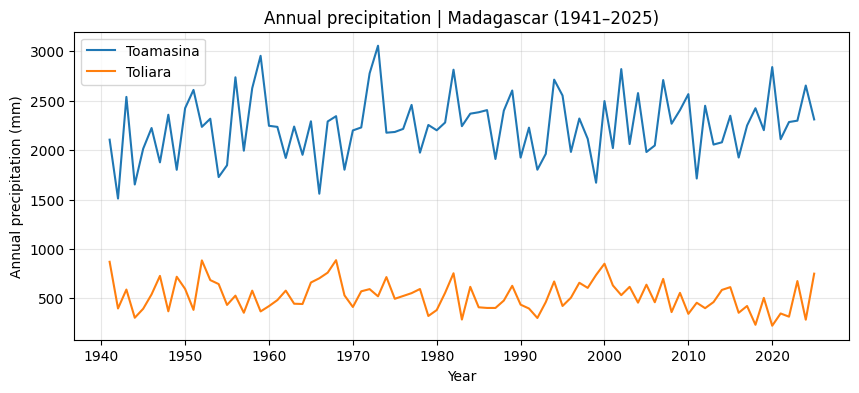

In [39]:
# 3. VISUALISE
# Compare annual precipitation at both stations

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(toamasina_annual.index, toamasina_annual,
        color="tab:blue", label="Toamasina")

ax.plot(toliara_annual.index, toliara_annual,
        color="tab:orange", label="Toliara")

ax.set(
    title="Annual precipitation | Madagascar (1941–2025)",
    xlabel="Year",
    ylabel="Annual precipitation (mm)"
)

ax.legend()
ax.grid(alpha=0.3)

# Export figure to Google Drive
fig.savefig(
    "/content/drive/MyDrive/geo_python_labs_2026/outputs/madagascar_precipitation_comparison.png",
    dpi=300, bbox_inches="tight"
)

plt.show()

**Anwswer to part 4 - Interpret**

Toamasina, on Madagascar's east coast, receives substantially more annual precipitation than Toliara in the southwest. Both locations experience considerable year-to-year variability. The contrast reflects Madagascar's geography: moist air from the Indian Ocean brings substantial rainfall to the eastern side of the island, while the southwest is much drier, partly because of the rain-shadow effect of the central highlands.

In [40]:
# 5. EXPORT
# Save processed annual data as separate CSV files

output_dir = "/content/drive/MyDrive/geo_python_labs_2026/outputs/"

# Export CSV files
toamasina_annual.to_csv(output_dir + "toamasina_annual_precipitation.csv")
toliara_annual.to_csv(output_dir + "toliara_annual_precipitation.csv")

# Figure already exported in Step 3 (VISUALISE)
# using fig.savefig() before plt.show()


### ⭐ Further challenges | Going beyond the basics

Finished early? Try these additional challenges to extend your analysis.

**⭐ Challenge 1 – Compare all three locations**

Add **Antananarivo** to your analysis. Plot annual mean temperature and annual total precipitation for all three locations.

- Which location is warmest? Which is wettest?
- How do the climates differ between the highlands, east coast and southwest?


**⭐⭐ Challenge 2 – How fast is Madagascar warming?**

**NB: This is challenge is advanced, and you are not expected to do or understand this!**

Using annual mean temperature for all three locations (1941–2025):

1. Plot the annual temperature time series for each location.
2. Add a **linear trend line** to each time series.
3. Calculate the rate of temperature change in **°C per decade**.
4. Compare the trends. Are all three locations warming at the same rate?

💡 **Hints:**
- Explore [NumPy `polyfit()` documentation](https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html) to fit a straight line to your data.
- Use `.index.year` to extract the years from your annual temperature series.
- `np.polyfit(x, y, 1)` returns the slope and intercept of a straight line. The `1` specifies a linear fit.
- Multiply the slope by **10** to express the temperature change in °C per decade.
- Use `ax.plot()` to add the fitted trend line to your figure.

**Think about:** How does the rate of temperature change compare with the differences in average temperature between the three locations?



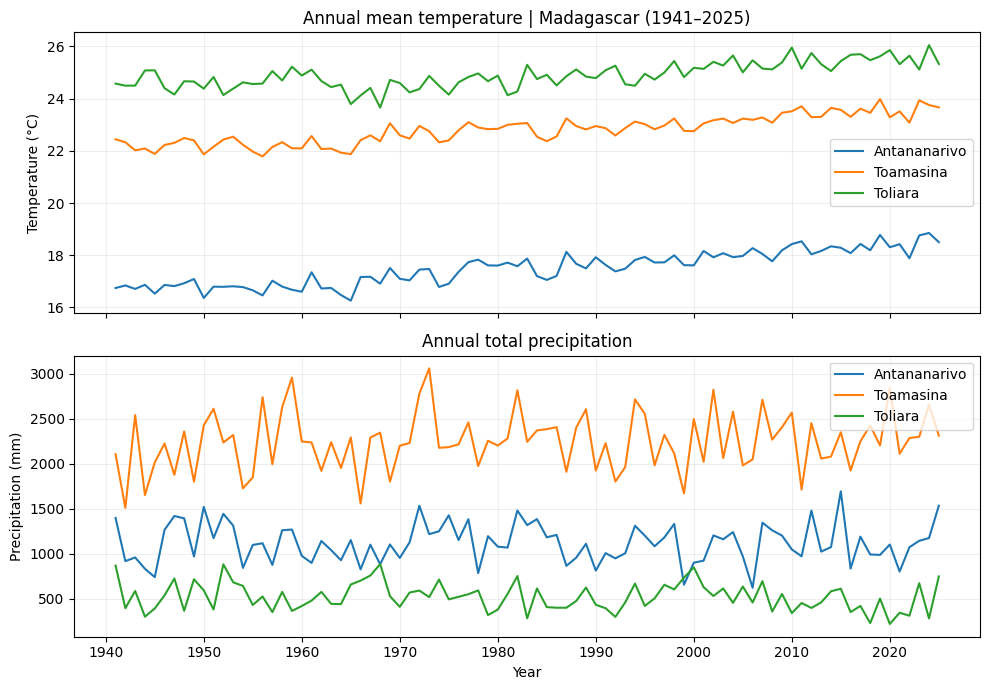

Mean annual temperature (°C)
Antananarivo: 17.5
Toamasina: 22.8
Toliara: 24.9

Mean annual precipitation (mm)
Antananarivo: 1119.0
Toamasina: 2244.0
Toliara: 523.0


In [43]:
### Solution Challenge 1 - All three locations ###

# 1. READ & PREPARE

# Dataset folder
data_dir = "/content/drive/MyDrive/geo_python_labs_2026/data/"

# File paths
antananarivo_file_path = data_dir + "Antananarivo_Madagascar_ERA5_daily_1941-2025.csv"
toamasina_file_path = data_dir + "Toamasina_Madagascar_ERA5_daily_1941-2025.csv"
toliara_file_path = data_dir + "Toliara_Madagascar_ERA5_daily_1941-2025.csv"

# Read CSV files
antananarivo = pd.read_csv(antananarivo_file_path)
toamasina = pd.read_csv(toamasina_file_path)
toliara = pd.read_csv(toliara_file_path)

# Convert dates
antananarivo["Date"] = pd.to_datetime(antananarivo["Date"], format="%d/%m/%Y")
toamasina["Date"] = pd.to_datetime(toamasina["Date"], format="%d/%m/%Y")
toliara["Date"] = pd.to_datetime(toliara["Date"], format="%d/%m/%Y")

# Set datetime index
antananarivo = antananarivo.set_index("Date")
toamasina = toamasina.set_index("Date")
toliara = toliara.set_index("Date")


# 2. ANALYSE

# Calculate annual mean temperature
temp_ant = antananarivo["Temperature_DegC"].resample("YS").mean()
temp_toa = toamasina["Temperature_DegC"].resample("YS").mean()
temp_tol = toliara["Temperature_DegC"].resample("YS").mean()

# Calculate annual total precipitation
rain_ant = antananarivo["Precipitation_mm"].resample("YS").sum()
rain_toa = toamasina["Precipitation_mm"].resample("YS").sum()
rain_tol = toliara["Precipitation_mm"].resample("YS").sum()


# 3. VISUALISE

# Create two panels
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Annual mean temperature
ax[0].plot(temp_ant.index, temp_ant, color="tab:blue", label="Antananarivo")
ax[0].plot(temp_toa.index, temp_toa, color="tab:orange", label="Toamasina")
ax[0].plot(temp_tol.index, temp_tol, color="tab:green", label="Toliara")

ax[0].set(
    title="Annual mean temperature | Madagascar (1941–2025)",
    ylabel="Temperature (°C)"
)

ax[0].legend()
ax[0].grid(alpha=0.2)

# Annual total precipitation
ax[1].plot(rain_ant.index, rain_ant, color="tab:blue", label="Antananarivo")
ax[1].plot(rain_toa.index, rain_toa, color="tab:orange", label="Toamasina")
ax[1].plot(rain_tol.index, rain_tol, color="tab:green", label="Toliara")

ax[1].set(
    title="Annual total precipitation",
    xlabel="Year",
    ylabel="Precipitation (mm)"
)

ax[1].legend()
ax[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()


# 4. INTERPRET

# Compare long-term averages
print("Mean annual temperature (°C)")
print("Antananarivo:", round(temp_ant.mean(), 1))
print("Toamasina:", round(temp_toa.mean(), 1))
print("Toliara:", round(temp_tol.mean(), 1))

print("\nMean annual precipitation (mm)")
print("Antananarivo:", round(rain_ant.mean(), 0))
print("Toamasina:", round(rain_toa.mean(), 0))
print("Toliara:", round(rain_tol.mean(), 0))

Temperature trends (1941–2025)
Antananarivo: +0.24 °C/decade
Toamasina: +0.19 °C/decade
Toliara: +0.14 °C/decade


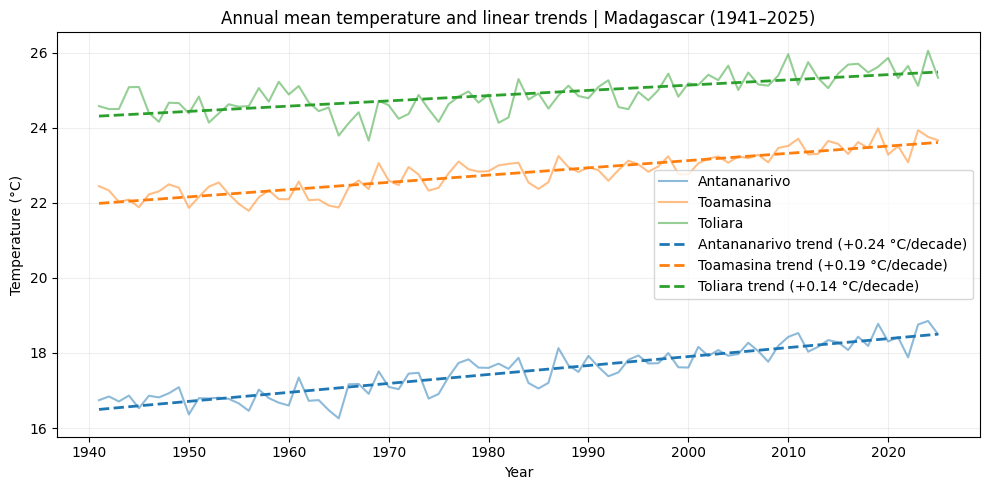

In [45]:
### Solution Challenge 2 - How fast is Madagascar warming? ###

### NOTE THIS IS ADVANCED AND NOT EXPECTED TO KNOW HOW TO DO THIS!!! ###

# Import NumPy
import numpy as np

# 1. ANALYSE
# Calculate linear trends for each location

years_ant = temp_ant.index.year
years_toa = temp_toa.index.year
years_tol = temp_tol.index.year

slope_ant, intercept_ant = np.polyfit(years_ant, temp_ant, 1)
slope_toa, intercept_toa = np.polyfit(years_toa, temp_toa, 1)
slope_tol, intercept_tol = np.polyfit(years_tol, temp_tol, 1)

# Convert slopes from °C/year to °C/decade
trend_ant = slope_ant * 10
trend_toa = slope_toa * 10
trend_tol = slope_tol * 10

print("Temperature trends (1941–2025)")
print(f"Antananarivo: {trend_ant:+.2f} °C/decade")
print(f"Toamasina: {trend_toa:+.2f} °C/decade")
print(f"Toliara: {trend_tol:+.2f} °C/decade")


# 2. VISUALISE

fig, ax = plt.subplots(figsize=(10, 5))

# Plot annual mean temperatures
ax.plot(temp_ant.index, temp_ant, color="tab:blue",
        alpha=0.5, label="Antananarivo")

ax.plot(temp_toa.index, temp_toa, color="tab:orange",
        alpha=0.5, label="Toamasina")

ax.plot(temp_tol.index, temp_tol, color="tab:green",
        alpha=0.5, label="Toliara")


# Add linear trend lines
ax.plot(temp_ant.index, slope_ant * years_ant + intercept_ant,
        color="tab:blue", linestyle="--", linewidth=2,
        label=f"Antananarivo trend ({trend_ant:+.2f} °C/decade)")

ax.plot(temp_toa.index, slope_toa * years_toa + intercept_toa,
        color="tab:orange", linestyle="--", linewidth=2,
        label=f"Toamasina trend ({trend_toa:+.2f} °C/decade)")

ax.plot(temp_tol.index, slope_tol * years_tol + intercept_tol,
        color="tab:green", linestyle="--", linewidth=2,
        label=f"Toliara trend ({trend_tol:+.2f} °C/decade)")


# Add labels and formatting
ax.set(
    title="Annual mean temperature and linear trends | Madagascar (1941–2025)",
    xlabel="Year",
    ylabel="Temperature (°C)"
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**End**